In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd().resolve().parent
sys.path.insert(0, str(ROOT))
import numpy as np
from src.data import SyntheticDataGenerator
import matplotlib.pyplot as plt

In [ ]:
#generate synthetic data
generator = SyntheticDataGenerator(n_samples=600, random_state=42)
separable = generator.linearly_separable()
nonseparable = generator.nonseparable(flip_fraction=0.17)
for dataset in [separable, nonseparable]:
    path = ROOT / 'Data' / f'{dataset.name}.csv'
    generator.save(dataset, path)
    print(dataset.name, dataset.X.shape, dict(zip(*np.unique(dataset.y, return_counts=True))))


synthetic_separable (600, 2) {np.int64(-1): np.int64(318), np.int64(1): np.int64(282)}
synthetic_nonseparable (600, 2) {np.int64(-1): np.int64(292), np.int64(1): np.int64(308)}


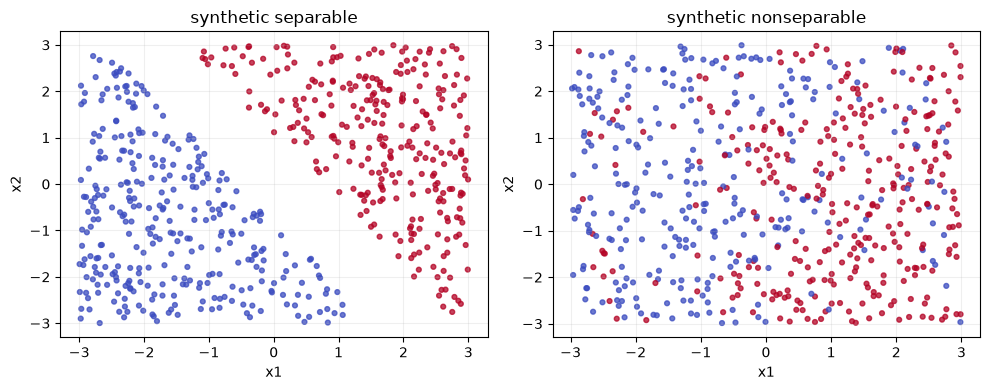

In [ ]:
#plot synthetic data
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, dataset in zip(axes, [separable, nonseparable]):
    ax.scatter(dataset.X[:,0], dataset.X[:,1], c=dataset.y, cmap='coolwarm', s=12, alpha=.75)
    ax.set(xlabel='x1', ylabel='x2', title=dataset.name.replace('_', ' '))
    ax.grid(alpha=.2)
plt.tight_layout()
plt.show()
